# 04. IPCA: Dinâmica Inflacionária

## Parte 0 _ Difusão • Dispersão • Concentração • Aceleração • Persistência

Os notebooks anteriores responderam:

- **02.ipca** $\to$ Quanto foi a inflação?
- **02.01 → 02.04** $\to$ Onde ocorreram os movimentos?
- **03.ipca_decomposicao** $\to$ A decomposição é consistente?

Neste notebook mudamos novamente a pergunta:

> **Qual é a natureza do processo inflacionário e o que os indicadores
> dizem sobre o momento atual da inflação?**

Um mesmo IPCA agregado pode representar situações muito diferentes:

```text
IPCA
 |
 +-- muitos preços subindo
 |
 +-- poucos preços subindo muito
 |
 +-- grande heterogeneidade entre componentes
 |
 +-- pressão persistente
 |
 +-- aceleração recente
 |
 +-- grandes movimentos positivos e negativos se compensando
```

O objetivo não é apenas calcular indicadores.

Queremos construir um diagnóstico integrado que permita responder:

* **Difusão** $\to\qquad$ A inflação está se espalhando?
* **Dispersão** $\to\qquad$ Os componentes estão se comportando de maneira muito diferente?
* **Concentração** $\to\qquad$ Poucos componentes dominam as pressões?
* **Momentum** $\to\qquad$ A inflação está ganhando ou perdendo força?
* **Inflação aparada** $\to\qquad$ A pressão permanece quando reduzimos a influência dos extremos?
* **Choques** $\to\qquad$ Onde estão as pressões?


Este notebook NÃO executa pipelines e NÃO altera o banco de dados.

### Objetivos

1. Medir a difusão da inflação.
2. Avaliar a tendência recente da difusão.
3. Medir a dispersão das variações entre subitens.
4. Medir a concentração das principais pressões.
5. Identificar quais subitens dominam os impactos.
6. Avaliar aceleração e desaceleração da inflação.
7. Investigar persistência de curto prazo.
8. Construir uma medida experimental de inflação subjacente.
9. Localizar choques por grupo.
10. Integrar os sinais em um painel de diagnóstico.

### 1. Estrutura analítica

```text
                      INFLAÇÃO
                          |
         +----------------+----------------+
         |                |                |
         v                v                v
      difusão         dispersão       concentração
         |                |                |
         v                v                v
    abrangência     heterogeneidade    dominância

                          +

                   dinâmica temporal
                          |
               +----------+----------+
               |                     |
               v                     v
          aceleração             persistência

                          +

                 inflação subjacente
                          |
                          v
                influência dos extremos
```

Nenhuma dessas medidas substitui o IPCA.

Elas permitem enxergar dimensões que o agregado sozinho não mostra.

### 2. Configuração do ambiente

In [67]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /home/moacir/projects/ml/analytics/inflation


### 3. Importações

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.patches import Patch
from sklearn.linear_model import LinearRegression

from src.database.connection import engine

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.4f}".format)

---

## PARTE I: DADOS



### 4. Carregar IPCA geral

In [69]:
ipca = pd.read_sql(
    """
    SELECT
        date,
        indice,
        acumulado12m
    FROM bcb.ipca_geral
    ORDER BY date;
    """,
    engine,
)

ipca["date"] = pd.to_datetime(
    ipca["date"]
)

ipca = (
    ipca
    .sort_values("date")
    .reset_index(drop=True)
)

ipca.tail(12)

,date,indice,acumulado12m
549,2025-09-01,0.4800,5.1700
550,2025-10-01,0.0900,4.6800
551,2025-11-01,0.1800,4.4600
552,2025-12-01,0.3300,4.2600
553,2026-01-01,0.3300,4.4400
554,2026-02-01,0.7000,3.8100
555,2026-03-01,0.8800,4.1400
556,2026-04-01,0.6700,4.3900
557,2026-05-01,0.5800,4.7200
558,2026-06-01,0.1600,4.6400


### 5. Carregar subitens

In [70]:
subitens = pd.read_sql(
    """
    SELECT
        date,
        categoria,
        categoria_nome,
        indice,
        peso
    FROM bcb.ipca_subitens
    ORDER BY date, categoria;
    """,
    engine,
)

subitens["date"] = pd.to_datetime(
    subitens["date"]
)

subitens["categoria"] = (
    subitens["categoria"]
    .astype(str)
)

subitens = (
    subitens
    .sort_values(
        [
            "date",
            "categoria",
        ]
    )
    .reset_index(drop=True)
)

#### 5.1 Contribuição e impacto

Mantemos:

$$
C_{i,t}=\pi_{i,t}\frac{w_{i,t}}{100}
$$

e:

$$
I_{i,t}=|C_{i,t}|
$$

In [71]:
subitens["contribuicao"] = (
    subitens["indice"]
    * subitens["peso"]
    / 100
)

subitens["impacto"] = (
    subitens["contribuicao"]
    .abs()
)

### 6. Cobertura

In [72]:
pd.DataFrame(
    [
        {
            "serie": "IPCA geral",
            "inicio": ipca["date"].min(),
            "fim": ipca["date"].max(),
            "observacoes": len(ipca),
        },
        {
            "serie": "Subitens",
            "inicio": subitens["date"].min(),
            "fim": subitens["date"].max(),
            "observacoes": len(subitens),
        },
    ]
)

,serie,inicio,fim,observacoes
0,IPCA geral,1979-12-01,2026-08-01,561
1,Subitens,2020-01-01,2026-08-01,30160


---

## PARTE II: DIFUSÃO



### 7. Conceito

A difusão mede a proporção de subitens com variação positiva.

$$
D_t=\frac{\sum_{i=1}^{N_t}\mathbf{1}(\pi_{i,t}>0)}{N_t}
$$

A difusão mede **abrangência**, não intensidade.

Por exemplo:

- $75\%$ significa que 3 de cada 4 subitens subiram;
- $50\%$ significa que metade subiu;
- $25\%$ significa que 1 de cada 4 subiu.

Não estabelecemos um threshold rígido para classificar difusão como
alta ou baixa. A leitura será feita em relação ao próprio histórico.

### 8. Calcular difusão

In [73]:
difusao = (
    subitens
    .assign(
        positivo=(
            subitens["indice"] > 0
        )
    )
    .groupby("date")
    .agg(
        componentes=(
            "categoria",
            "count",
        ),
        positivos=(
            "positivo",
            "sum",
        ),
    )
)

difusao["difusao"] = (
    difusao["positivos"]
    / difusao["componentes"]
)

difusao["mm3"] = (
    difusao["difusao"]
    .rolling(3)
    .mean()
)

difusao["mm6"] = (
    difusao["difusao"]
    .rolling(6)
    .mean()
)

difusao["delta_difusao"] = (
    difusao["difusao"]
    .diff()
)

difusao.tail(12)

,componentes,positivos,difusao,mm3,mm6,delta_difusao
date,,,,,,
2025-09-01,377,197,0.5225,0.5287,0.5645,-0.0451
2025-10-01,377,197,0.5225,0.5376,0.5402,0.0000
2025-11-01,377,210,0.5570,0.5340,0.5336,0.0345
2025-12-01,377,228,0.6048,0.5615,0.5451,0.0477
2026-01-01,377,241,0.6393,0.6004,0.5690,0.0345
2026-02-01,377,231,0.6127,0.6189,0.5765,-0.0265
2026-03-01,377,254,0.6737,0.6419,0.6017,0.0610
2026-04-01,377,246,0.6525,0.6463,0.6233,-0.0212
2026-05-01,377,245,0.6499,0.6587,0.6388,-0.0027


### 9. Evolução histórica da difusão

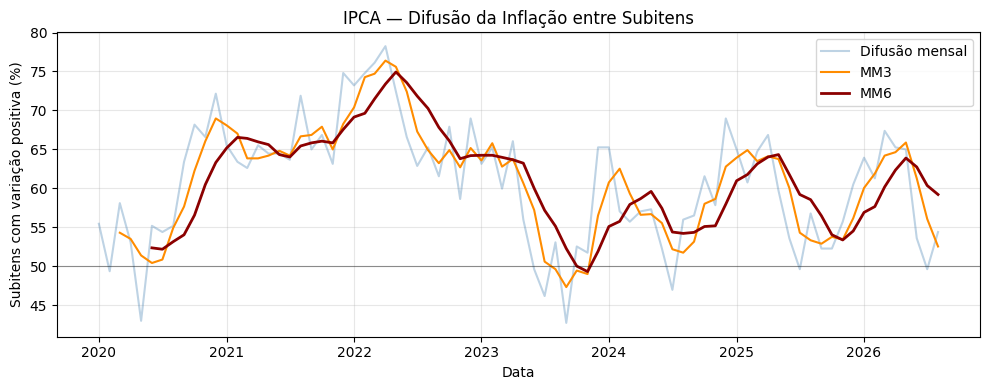

In [109]:
data_inicio_10a = (
    difusao.index.max()
    - pd.DateOffset(years=10)
)

difusao_10a = (
    difusao[
        difusao.index
        >= data_inicio_10a
    ]
    .copy()
)

plt.figure(figsize=(10, 4))

plt.plot(
    difusao_10a.index,
    difusao_10a["difusao"] * 100,
    alpha=0.35,
    color="steelblue",
    label="Difusão mensal",
)

plt.plot(
    difusao_10a.index,
    difusao_10a["mm3"] * 100,
    color="darkorange",
    label="MM3",
)

plt.plot(
    difusao_10a.index,
    difusao_10a["mm6"] * 100,
    color="darkred",
    linewidth=2,
    label="MM6",
)

plt.axhline(
    50,
    color="black",
    linewidth=0.8,
    alpha=0.4,
)

plt.title(
    "IPCA — Difusão da Inflação entre Subitens"
)

plt.xlabel("Data")
plt.ylabel(
    "Subitens com variação positiva (%)"
)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend()

plt.tight_layout()
plt.show()

### 10. Tendência recente da difusão

Para complementar MM3 e MM6, avaliamos os últimos 13 meses por meio de uma tendência linear:

$$
\widehat{D}_t=\beta_0+\beta_1t
$$

O slope $\beta_1$ indica a direção linear do período:

$$
\beta_1>0\Rightarrow\text{difusão em tendência crescente}
$$

$$
\beta_1<0\Rightarrow\text{difusão em tendência decrescente}
$$
A regressão é utilizada apenas como **descrição da janela observada**,e não como previsão




In [75]:
difusao_recente = (
    difusao
    .tail(13)
    .copy()
)

X_dif = np.arange(
    len(difusao_recente)
).reshape(-1, 1)

y_dif = (
    difusao_recente["difusao"]
    .values
    * 100
)

modelo_dif = (
    LinearRegression()
    .fit(
        X_dif,
        y_dif,
    )
)

difusao_recente["tendencia"] = (
    modelo_dif.predict(
        X_dif
    )
)

slope_difusao = (
    modelo_dif.coef_[0]
)

max_idx = (
    difusao_recente["difusao"]
    .idxmax()
)

min_idx = (
    difusao_recente["difusao"]
    .idxmin()
)

max_val = (
    difusao_recente.loc[
        max_idx,
        "difusao",
    ]
    * 100
)

min_val = (
    difusao_recente.loc[
        min_idx,
        "difusao",
    ]
    * 100
)

atual_difusao = (
    difusao_recente[
        "difusao"
    ]
    .iloc[-1]
    * 100
)

cor_slope_dif = (
    "tab:red"
    if slope_difusao > 0
    else "tab:green"
)

seta_dif = (
    "↑"
    if slope_difusao > 0
    else "↓"
)

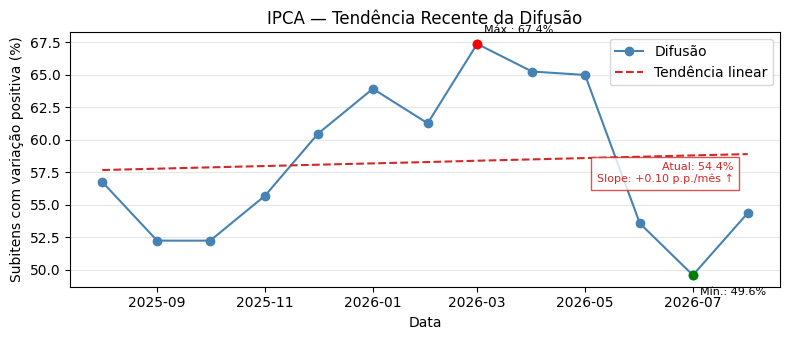

In [110]:
plt.figure(figsize=(8, 3.5))

plt.plot(
    difusao_recente.index,
    difusao_recente["difusao"] * 100,
    color="steelblue",
    marker="o",
    linewidth=1.5,
    label="Difusão",
)

plt.plot(
    difusao_recente.index,
    difusao_recente["tendencia"],
    "--",
    color=cor_slope_dif,
    linewidth=1.5,
    label="Tendência linear",
)

plt.scatter(
    max_idx,
    max_val,
    color="red",
    zorder=5,
)

plt.scatter(
    min_idx,
    min_val,
    color="green",
    zorder=5,
)

plt.annotate(
    f"Máx.: {max_val:.1f}%",
    (max_idx, max_val),
    xytext=(5, 8),
    textcoords="offset points",
    fontsize=8,
)

plt.annotate(
    f"Mín.: {min_val:.1f}%",
    (min_idx, min_val),
    xytext=(5, -14),
    textcoords="offset points",
    fontsize=8,
)

plt.annotate(
    (
        f"Atual: {atual_difusao:.1f}%\n"
        f"Slope: {slope_difusao:+.2f} p.p./mês {seta_dif}"
    ),
    (
        difusao_recente.index[-1],
        atual_difusao,
    ),
    xytext=(-10, 22),
    textcoords="offset points",
    ha="right",
    fontsize=8,
    color=cor_slope_dif,
    bbox=dict(
        facecolor="white",
        edgecolor=cor_slope_dif,
        alpha=0.8,
    ),
)

plt.title(
    "IPCA — Tendência Recente da Difusão"
)

plt.xlabel("Data")
plt.ylabel(
    "Subitens com variação positiva (%)"
)

plt.grid(
    True,
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()
plt.show()

### 11. Variação mensal da difusão

$$
\Delta D_t=D_t-D_{t-1}
$$

Assim:

- $\Delta D_t>0$ indica aumento da abrangência;
- $\Delta D_t<0$ indica redução da abrangência.

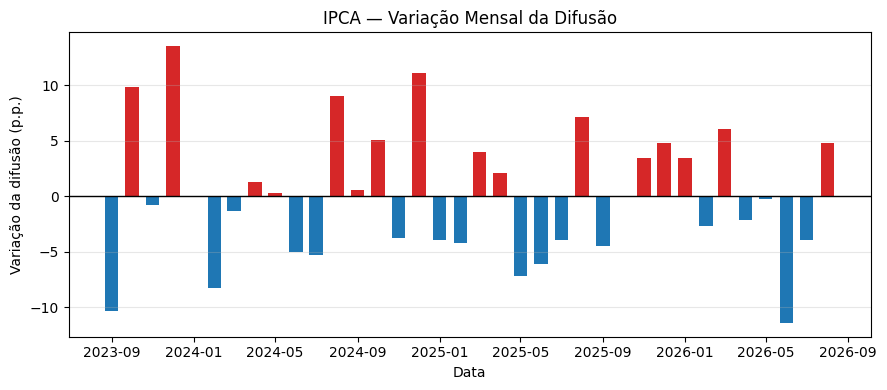

In [111]:
difusao_delta_36m = (
    difusao
    .tail(36)
    .copy()
)

cores = np.where(
    difusao_delta_36m[
        "delta_difusao"
    ] >= 0,
    "tab:red",
    "tab:blue",
)

plt.figure(figsize=(9, 4))

plt.bar(
    difusao_delta_36m.index,
    difusao_delta_36m[
        "delta_difusao"
    ] * 100,
    color=cores,
    width=20,
)

plt.axhline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    "IPCA — Variação Mensal da Difusão"
)

plt.xlabel("Data")
plt.ylabel("Variação da difusão (p.p.)")

plt.grid(
    True,
    axis="y",
    alpha=0.3,
)

plt.tight_layout()
plt.show()

### 12. Leitura da difusão

A análise conjunta permite observar:

```text
          nível atual
               +
           MM3 / MM6
               +
           Δ difusão
               +
             slope
               ↓
 abrangência e direção recente
```

Exemplos de investigação:

- difusão elevada e slope positivo: altas disseminadas e ganhando abrangência;
- difusão elevada e slope negativo: altas ainda disseminadas, mas perdendo abrangência;
- difusão recuando com IPCA desacelerando: possível processo de desinflação mais amplo;
- difusão crescente com IPCA estável: pressões podem estar se espalhando antes de aparecerem integralmente no agregado.

---

## PARTE III: DISPERSÃO



### 13. Conceito

Difusão responde:

> Quantos componentes estão subindo?

Dispersão responde:

> Quão diferentes são os movimentos entre eles?

Utilizamos:

$$
\sigma_{\pi,t}=\sqrt{\frac{\sum_i(\pi_{i,t}-\bar{\pi}_t)^2}{N_t-1}}
$$

e:

$$
IQR_t=Q_{0.75,t}-Q_{0.25,t}
$$

O IQR é menos sensível a valores extremos.

### 14. Calcular dispersão

In [78]:
dispersao = (
    subitens
    .groupby("date")
    .agg(
        media=(
            "indice",
            "mean",
        ),
        mediana=(
            "indice",
            "median",
        ),
        desvio_padrao=(
            "indice",
            "std",
        ),
        minimo=(
            "indice",
            "min",
        ),
        maximo=(
            "indice",
            "max",
        ),
    )
)

q1 = (
    subitens
    .groupby("date")["indice"]
    .quantile(0.25)
)

q3 = (
    subitens
    .groupby("date")["indice"]
    .quantile(0.75)
)

dispersao["iqr"] = (
    q3 - q1
)

dispersao["amplitude"] = (
    dispersao["maximo"]
    - dispersao["minimo"]
)

dispersao.tail(12)

,media,mediana,desvio_padrao,minimo,maximo,iqr,amplitude
date,,,,,,,
2025-09-01,-0.0911,0.0800,3.6956,-30.8300,33.5000,1.2800,64.3300
2025-10-01,0.1008,0.0700,2.2723,-22.0000,10.4700,1.2400,32.4700
2025-11-01,0.1540,0.1800,2.6042,-21.1800,12.7700,1.3600,33.9500
2025-12-01,0.5194,0.2300,2.9230,-16.5800,21.8100,1.2500,38.3900
2026-01-01,0.6852,0.3500,3.0575,-17.2300,28.8200,1.3500,46.0500
2026-02-01,0.3629,0.3300,2.9347,-24.3500,25.2900,1.5400,49.6400
2026-03-01,1.0738,0.4400,3.4419,-13.2000,28.0800,1.3800,41.2800
2026-04-01,0.8860,0.5200,3.0284,-14.4500,26.6300,1.5900,41.0800
2026-05-01,0.6141,0.3800,4.1719,-11.4300,44.6900,1.2400,56.1200


### 15. Evolução da dispersão

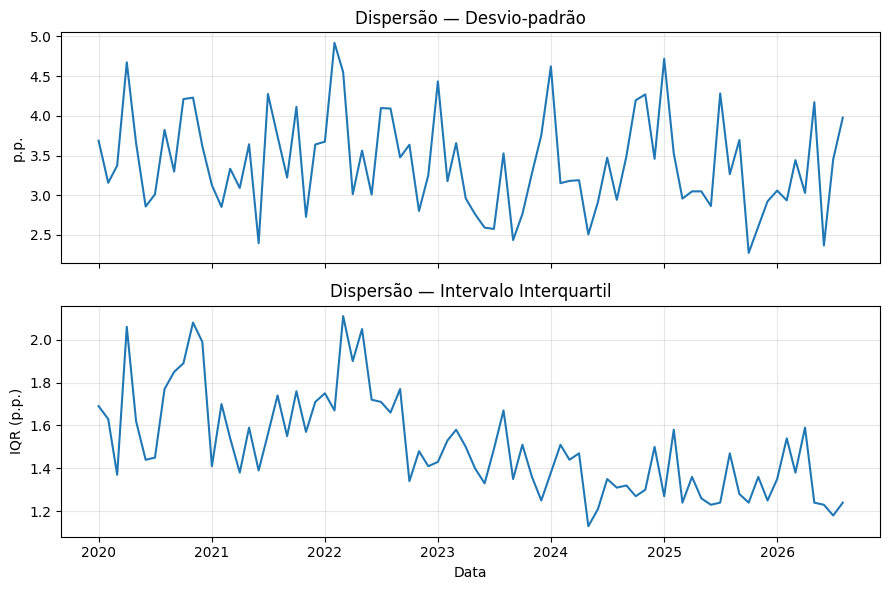

In [112]:
dispersao_10a = (
    dispersao[
        dispersao.index
        >= (
            dispersao.index.max()
            - pd.DateOffset(years=10)
        )
    ]
)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(9, 6),
    sharex=True,
)

axes[0].plot(
    dispersao_10a.index,
    dispersao_10a["desvio_padrao"],
)

axes[0].set_title(
    "Dispersão — Desvio-padrão"
)

axes[0].set_ylabel("p.p.")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    dispersao_10a.index,
    dispersao_10a["iqr"],
)

axes[1].set_title(
    "Dispersão — Intervalo Interquartil"
)

axes[1].set_xlabel("Data")
axes[1].set_ylabel("IQR (p.p.)")

axes[1].grid(
    True,
    alpha=0.3,
)

plt.tight_layout()
plt.show()

### 16. Dispersão atual versus referência recente

Além de observar a série, comparamos o momento atual com a mediana
dos últimos 60 meses.

Isso responde:

> Os movimentos dos componentes estão mais heterogêneos que o padrão
> recente?

In [80]:
dispersao_atual = (
    dispersao
    .iloc[-1]
)

dispersao_referencia = (
    dispersao
    .tail(60)
    .median()
)

pd.DataFrame(
    {
        "atual": dispersao_atual[
            [
                "desvio_padrao",
                "iqr",
                "amplitude",
            ]
        ],
        "mediana_5a": dispersao_referencia[
            [
                "desvio_padrao",
                "iqr",
                "amplitude",
            ]
        ],
    }
)

,atual,mediana_5a
desvio_padrao,3.9776,3.2581
iqr,1.2400,1.4050
amplitude,73.2900,42.4550


---

## PARTE IV: CONCENTRAÇÃO DAS PRESSÕES



### 17. Conceito

O impacto mede:

$$
I_{i,t}=|C_{i,t}|
$$

e o impacto total:

$$
I_t^{total}=\sum_i I_{i,t}
$$

A concentração nos $k$ maiores impactos é:

$$
K_{k,t}=\frac{\sum_{i \in TopK_t}I_{i,t}}{\sum_iI_{i,t}}
$$

Quanto maior $K_{k,t}$, maior a dominância de poucos componentes.

### 18. Função de concentração

In [81]:
def concentracao_top_n(
    grupo,
    n,
):
    impactos = (
        grupo["impacto"]
        .sort_values(
            ascending=False
        )
    )

    impacto_total = impactos.sum()

    if impacto_total == 0:
        return 0.0

    return (
        impactos.head(n).sum()
        / impacto_total
    )

### 19. Calcular concentração

In [82]:
concentracao = pd.DataFrame(
    {
        "top5": (
            subitens
            .groupby("date")
            .apply(
                concentracao_top_n,
                n=5,
                include_groups=False,
            )
        ),
        "top10": (
            subitens
            .groupby("date")
            .apply(
                concentracao_top_n,
                n=10,
                include_groups=False,
            )
        ),
        "top20": (
            subitens
            .groupby("date")
            .apply(
                concentracao_top_n,
                n=20,
                include_groups=False,
            )
        ),
    }
)

concentracao.tail(12)

,top5,top10,top20
date,,,
2025-09-01,0.4867,0.5597,0.6671
2025-10-01,0.2953,0.4031,0.5695
2025-11-01,0.2831,0.4097,0.5516
2025-12-01,0.3319,0.4487,0.5881
2026-01-01,0.3515,0.5122,0.6632
2026-02-01,0.3202,0.4291,0.5670
2026-03-01,0.3804,0.4661,0.6123
2026-04-01,0.3392,0.4252,0.5575
2026-05-01,0.4069,0.5310,0.6337


### 20. Evolução da concentração

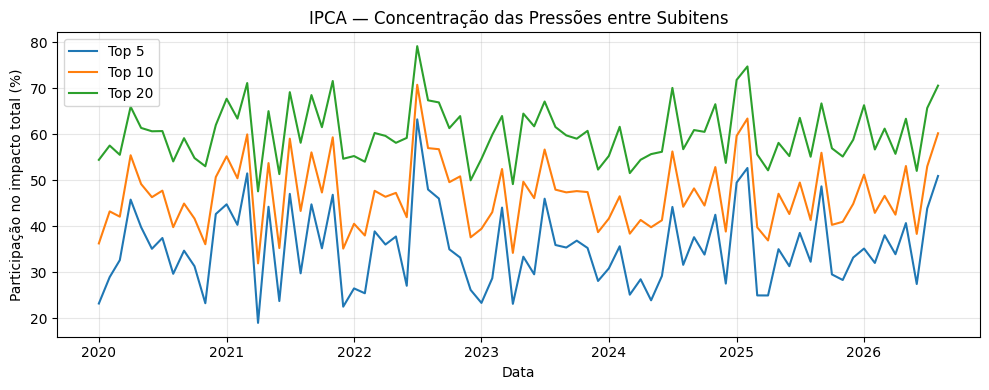

In [83]:
concentracao_10a = (
    concentracao[
        concentracao.index
        >= (
            concentracao.index.max()
            - pd.DateOffset(years=10)
        )
    ]
)

plt.figure(figsize=(10, 4))

plt.plot(
    concentracao_10a.index,
    concentracao_10a["top5"] * 100,
    label="Top 5",
)

plt.plot(
    concentracao_10a.index,
    concentracao_10a["top10"] * 100,
    label="Top 10",
)

plt.plot(
    concentracao_10a.index,
    concentracao_10a["top20"] * 100,
    label="Top 20",
)

plt.title(
    "IPCA — Concentração das Pressões entre Subitens"
)

plt.xlabel("Data")
plt.ylabel(
    "Participação no impacto total (%)"
)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend()

plt.tight_layout()
plt.show()

### 21. Quem domina as pressões no mês atual?

Concentração responde:

> Quanto os maiores componentes dominam?

Agora identificamos:

> Quais são esses componentes?

In [84]:
ultimo_mes_subitens = (
    subitens["date"].max()
)

top_impactos_atual = (
    subitens[
        subitens["date"]
        == ultimo_mes_subitens
    ]
    .nlargest(
        10,
        "impacto",
    )[
        [
            "categoria_nome",
            "indice",
            "peso",
            "contribuicao",
            "impacto",
        ]
    ]
)

top_impactos_atual

,categoria_nome,indice,peso,contribuicao,impacto
29982,Energia elétrica residencial,-7.6300,4.2960,-0.3278,0.3278
30132,Cigarro,19.5900,0.5785,0.1133,0.1133
30050,Passagem aérea,-13.1700,0.8159,-0.1075,0.1075
29798,Batata-inglesa,-19.8900,0.2295,-0.0456,0.0456
30069,Gasolina,-0.5900,5.1423,-0.0303,0.0303
29804,Tomate,-10.9400,0.2458,-0.0269,0.0269
30062,Conserto de automóvel,1.3500,1.8417,0.0249,0.0249
30070,Etanol,-3.9500,0.6201,-0.0245,0.0245
29805,Cebola,-11.0700,0.1831,-0.0203,0.0203
30096,Plano de saúde,0.4200,4.1405,0.0174,0.0174


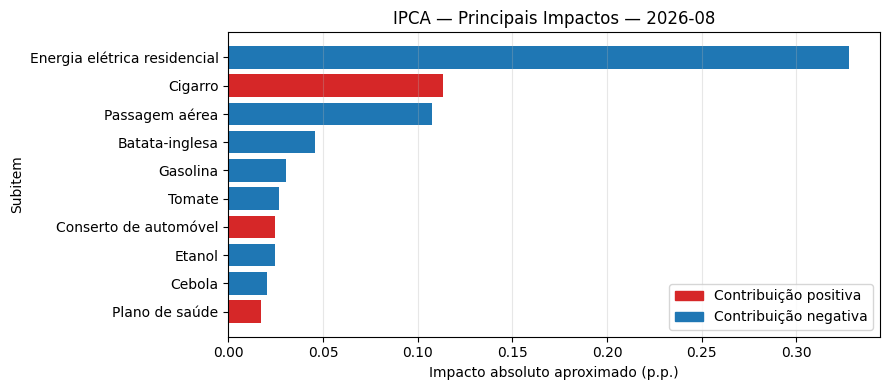

In [113]:
top_plot = (
    top_impactos_atual
    .sort_values("impacto")
)

cores = np.where(
    top_plot["contribuicao"] >= 0,
    "tab:red",
    "tab:blue",
)

plt.figure(figsize=(9, 4))

plt.barh(
    top_plot["categoria_nome"],
    top_plot["impacto"],
    color=cores,
)

plt.title(
    f"IPCA — Principais Impactos — {ultimo_mes_subitens:%Y-%m}"
)

plt.xlabel(
    "Impacto absoluto aproximado (p.p.)"
)

plt.ylabel("Subitem")

plt.grid(
    True,
    axis="x",
    alpha=0.3,
)

legenda = [
    Patch(
        color="tab:red",
        label="Contribuição positiva",
    ),
    Patch(
        color="tab:blue",
        label="Contribuição negativa",
    ),
]

plt.legend(
    handles=legenda,
    loc="lower right",
)

plt.tight_layout()
plt.show()

### 22. Difusão versus concentração

* difusão $\to\qquad$ quantos componentes sobem?
* concentração $\to\qquad$ poucos componentes dominam as pressões?


Essa combinação pode distinguir:

- movimentos amplos e distribuídos;
- movimentos amplos, mas dominados por poucos componentes;
- movimentos concentrados;
- períodos de baixa pressão generalizada.

---

## PARTE V: ACELERAÇÃO E MOMENTUM



### 23. Momentum

Utilizamos a média móvel de três meses:

$$
M_t^{(3)}=\frac{\pi_t+\pi_{t-1}+\pi_{t-2}}{3}
$$

e a média móvel de seis meses:

$$
M_t^{(6)}=\frac{\sum_{j=0}^{5}\pi_{t-j}}{6}
$$

In [86]:
ipca["mm3"] = (
    ipca["indice"]
    .rolling(3)
    .mean()
)

ipca["mm6"] = (
    ipca["indice"]
    .rolling(6)
    .mean()
)

### 24. Aceleração

Definimos:

$$
A_t=M_t^{(3)}-M_{t-3}^{(3)}
$$

Assim:

- $A_t>0$ indica aceleração da média de curto prazo;
- $A_t<0$ indica desaceleração.

In [87]:
ipca["aceleracao_3m"] = (
    ipca["mm3"]
    - ipca["mm3"].shift(3)
)

ipca[
    [
        "date",
        "indice",
        "mm3",
        "aceleracao_3m",
    ]
].tail(12)

,date,indice,mm3,aceleracao_3m
549,2025-09-01,0.4800,0.2100,-0.1000
550,2025-10-01,0.0900,0.1533,-0.1000
551,2025-11-01,0.1800,0.2500,0.1200
552,2025-12-01,0.3300,0.2000,-0.0100
553,2026-01-01,0.3300,0.2800,0.1267
554,2026-02-01,0.7000,0.4533,0.2033
555,2026-03-01,0.8800,0.6367,0.4367
556,2026-04-01,0.6700,0.7500,0.4700
557,2026-05-01,0.5800,0.7100,0.2567
558,2026-06-01,0.1600,0.4700,-0.1667


### 25. Evolução da aceleração

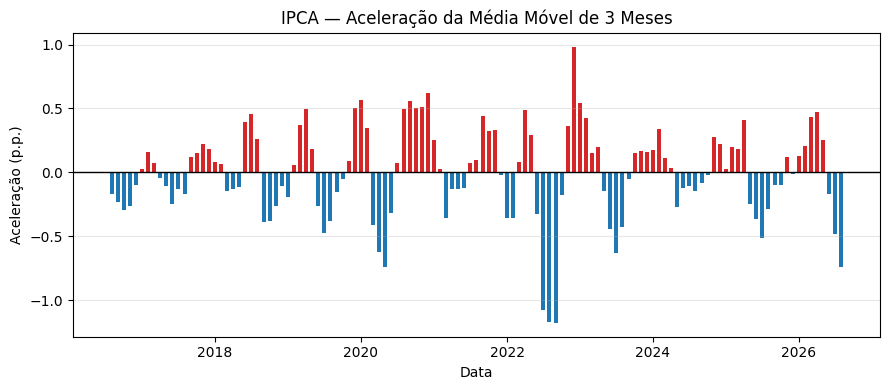

In [114]:
ipca_10a = (
    ipca[
        ipca["date"]
        >= (
            ipca["date"].max()
            - pd.DateOffset(years=10)
        )
    ]
    .copy()
)

cores = np.where(
    ipca_10a["aceleracao_3m"] >= 0,
    "tab:red",
    "tab:blue",
)

plt.figure(figsize=(9, 4))

plt.bar(
    ipca_10a["date"],
    ipca_10a["aceleracao_3m"],
    color=cores,
    width=20,
)

plt.axhline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    "IPCA — Aceleração da Média Móvel de 3 Meses"
)

plt.xlabel("Data")
plt.ylabel("Aceleração (p.p.)")

plt.grid(
    True,
    axis="y",
    alpha=0.3,
)

plt.tight_layout()
plt.show()

### 26. Tendência recente do momentum

Como informação complementar, estimamos:

$$
\widehat{M}_t^{(3)}=\alpha+\beta t
$$

O slope $\beta$ mede a direção linear da MM3 na janela recente.

Novamente, trata-se de descrição, não de previsão.

In [89]:
momentum_recente = (
    ipca[
        [
            "date",
            "indice",
            "mm3",
            "mm6",
            "aceleracao_3m",
        ]
    ]
    .dropna()
    .tail(13)
    .copy()
)

X_mom = np.arange(
    len(momentum_recente)
).reshape(-1, 1)

modelo_mom = (
    LinearRegression()
    .fit(
        X_mom,
        momentum_recente["mm3"],
    )
)

momentum_recente[
    "tendencia_mm3"
] = (
    modelo_mom.predict(
        X_mom
    )
)

slope_momentum = (
    modelo_mom.coef_[0]
)

cor_slope_mom = (
    "tab:red"
    if slope_momentum > 0
    else "tab:green"
)

seta_mom = (
    "↑"
    if slope_momentum > 0
    else "↓"
)

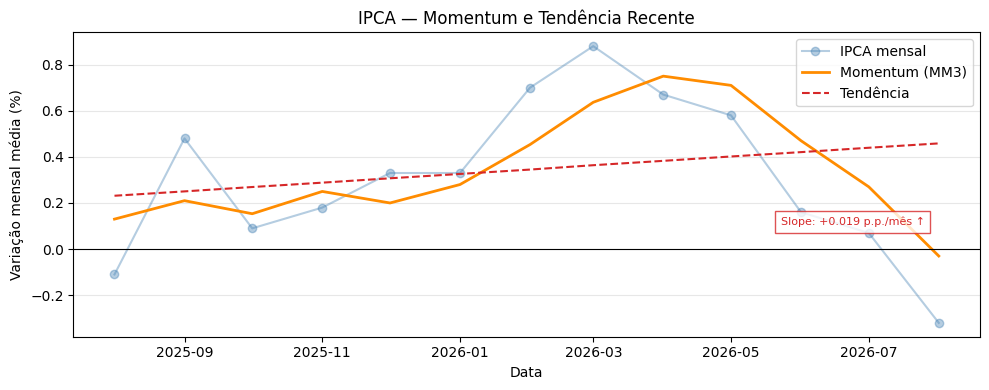

In [90]:
plt.figure(figsize=(10, 4))

plt.plot(
    momentum_recente["date"],
    momentum_recente["indice"],
    color="steelblue",
    alpha=0.4,
    marker="o",
    label="IPCA mensal",
)

plt.plot(
    momentum_recente["date"],
    momentum_recente["mm3"],
    color="darkorange",
    linewidth=2,
    label="Momentum (MM3)",
)

plt.plot(
    momentum_recente["date"],
    momentum_recente[
        "tendencia_mm3"
    ],
    "--",
    color=cor_slope_mom,
    linewidth=1.5,
    label="Tendência",
)

plt.annotate(
    (
        f"Slope: {slope_momentum:+.3f} "
        f"p.p./mês {seta_mom}"
    ),
    (
        momentum_recente["date"].iloc[-1],
        momentum_recente["mm3"].iloc[-1],
    ),
    xytext=(-10, 22),
    textcoords="offset points",
    ha="right",
    fontsize=8,
    color=cor_slope_mom,
    bbox=dict(
        facecolor="white",
        edgecolor=cor_slope_mom,
        alpha=0.8,
    ),
)

plt.axhline(
    0,
    color="black",
    linewidth=0.8,
)

plt.title(
    "IPCA — Momentum e Tendência Recente"
)

plt.xlabel("Data")
plt.ylabel("Variação mensal média (%)")

plt.grid(
    True,
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()
plt.show()

---

## PARTE VI: PERSISTÊNCIA



### 27. Curto versus médio prazo

A comparação entre MM3 e MM6 ajuda a avaliar se a dinâmica mais recente
está acima ou abaixo de uma referência um pouco mais longa.

Definimos:

$$
G_t^{CM}=M_t^{(3)}-M_t^{(6)}
$$

Se:

$$
G_t^{CM}>0
$$

o curto prazo está acima do médio prazo.

Se:

$$
G_t^{CM}<0
$$

o curto prazo está abaixo do médio prazo.

In [91]:
ipca["gap_curto_medio"] = (
    ipca["mm3"]
    - ipca["mm6"]
)

ipca[
    [
        "date",
        "mm3",
        "mm6",
        "gap_curto_medio",
    ]
].tail(12)

,date,mm3,mm6,gap_curto_medio
549,2025-09-01,0.2100,0.2600,-0.0500
550,2025-10-01,0.1533,0.2033,-0.0500
551,2025-11-01,0.2500,0.1900,0.0600
552,2025-12-01,0.2000,0.2050,-0.0050
553,2026-01-01,0.2800,0.2167,0.0633
554,2026-02-01,0.4533,0.3517,0.1017
555,2026-03-01,0.6367,0.4183,0.2183
556,2026-04-01,0.7500,0.5150,0.2350
557,2026-05-01,0.7100,0.5817,0.1283
558,2026-06-01,0.4700,0.5533,-0.0833


### 28. Dinâmica de curto e médio prazo

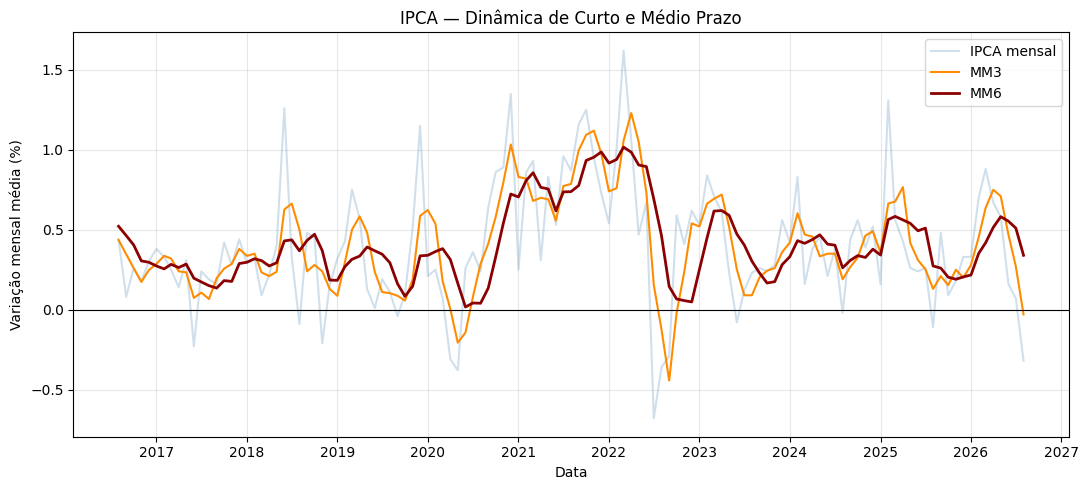

In [92]:
plt.figure(figsize=(11, 5))

plt.plot(
    ipca_10a["date"],
    ipca_10a["indice"],
    alpha=0.25,
    color="steelblue",
    label="IPCA mensal",
)

plt.plot(
    ipca_10a["date"],
    ipca_10a["mm3"],
    color="darkorange",
    label="MM3",
)

plt.plot(
    ipca_10a["date"],
    ipca_10a["mm6"],
    color="darkred",
    linewidth=2,
    label="MM6",
)

plt.axhline(
    0,
    color="black",
    linewidth=0.8,
)

plt.title(
    "IPCA — Dinâmica de Curto e Médio Prazo"
)

plt.xlabel("Data")
plt.ylabel("Variação mensal média (%)")

plt.grid(
    True,
    alpha=0.3,
)

plt.legend()

plt.tight_layout()
plt.show()

---

## PARTE VII: INFLAÇÃO SUBJACENTE EXPERIMENTAL



### 29. Conceito

A inflação cheia pode ser afetada por movimentos extremos.

Para investigar o centro da distribuição, construímos uma média
aparada experimental:

1. ordenamos os subitens por variação;
2. removemos determinada proporção de cada cauda;
3. calculamos a média ponderada pelo peso do conjunto restante.

A medida NÃO é um núcleo oficial de inflação.

### 30. Função de média aparada

In [93]:
def media_aparada(
    grupo,
    proporcao=0.20,
):
    dados = (
        grupo
        .sort_values("indice")
        .copy()
    )

    n = len(dados)

    corte = int(
        n * proporcao
    )

    if (
        n == 0
        or 2 * corte >= n
    ):
        return np.nan

    miolo = dados.iloc[
        corte:
        n - corte
    ]

    if miolo["peso"].sum() == 0:
        return np.nan

    return np.average(
        miolo["indice"],
        weights=miolo["peso"],
    )

### 31. Sensibilidade ao corte

Calculamos:

$$
10\%,
\quad
15\%,
\quad
20\%,
\quad
25\%
$$

para verificar se a medida muda demasiadamente com a escolha da apara.

In [94]:
aparas = {}

for proporcao in [
    0.10,
    0.15,
    0.20,
    0.25,
]:

    nome = (
        f"aparada_{int(proporcao * 100)}"
    )

    aparas[nome] = (
        subitens
        .groupby("date")
        .apply(
            media_aparada,
            proporcao=proporcao,
            include_groups=False,
        )
    )

inflacao_aparada = pd.DataFrame(
    aparas
)

inflacao_aparada.tail(12)

,aparada_10,aparada_15,aparada_20,aparada_25
date,,,,
2025-09-01,0.1449,0.1773,0.1882,0.1656
2025-10-01,0.2315,0.2350,0.2179,0.2043
2025-11-01,0.2088,0.2380,0.1738,0.1699
2025-12-01,0.3601,0.3396,0.3026,0.3174
2026-01-01,0.5476,0.3966,0.4048,0.4082
2026-02-01,0.3435,0.3408,0.3462,0.3719
2026-03-01,0.4388,0.4118,0.4239,0.4249
2026-04-01,0.6298,0.5963,0.4694,0.4300
2026-05-01,0.2686,0.3448,0.3555,0.3583


In [95]:
ultimo_mes_aparada = (
    inflacao_aparada
    .dropna(how="all")
    .index
    .max()
)

sensibilidade_apara = (
    inflacao_aparada
    .loc[
        ultimo_mes_aparada
    ]
    .rename("inflacao")
    .reset_index()
    .rename(
        columns={
            "index": "metodo"
        }
    )
)

sensibilidade_apara["corte"] = (
    sensibilidade_apara["metodo"]
    .str.extract(r"(\d+)")
    .astype(int)
)

sensibilidade_apara = (
    sensibilidade_apara
    .sort_values("corte")
)

sensibilidade_apara

,metodo,inflacao,corte
0,aparada_10,0.1431,10
1,aparada_15,0.1278,15
2,aparada_20,0.1213,20
3,aparada_25,0.2069,25


### 32. IPCA cheio versus aparada de 20%

In [96]:
comparacao_aparada = (
    ipca[
        [
            "date",
            "indice",
        ]
    ]
    .set_index("date")
    .join(
        inflacao_aparada[
            ["aparada_20"]
        ],
        how="inner",
    )
)

comparacao_aparada["gap_aparada"] = (
    comparacao_aparada["indice"]
    - comparacao_aparada["aparada_20"]
)

comparacao_aparada_36m = (
    comparacao_aparada
    .tail(36)
    .copy()
)

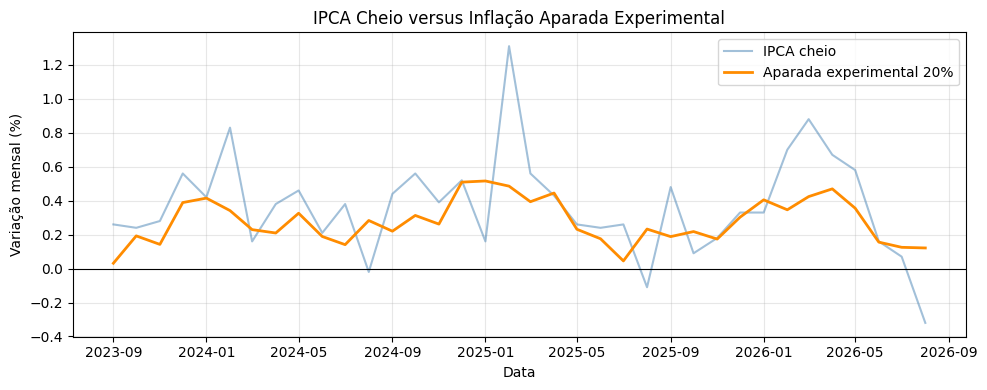

In [116]:
plt.figure(figsize=(10, 4))

plt.plot(
    comparacao_aparada_36m.index,
    comparacao_aparada_36m["indice"],
    color="steelblue",
    alpha=0.5,
    label="IPCA cheio",
)

plt.plot(
    comparacao_aparada_36m.index,
    comparacao_aparada_36m["aparada_20"],
    color="darkorange",
    linewidth=2,
    label="Aparada experimental 20%",
)

plt.axhline(
    0,
    color="black",
    linewidth=0.8,
)

plt.title(
    "IPCA Cheio versus Inflação Aparada Experimental"
)

plt.xlabel("Data")
plt.ylabel("Variação mensal (%)")

plt.grid(
    True,
    alpha=0.3,
)

plt.legend()

plt.tight_layout()
plt.show()

### 33. Gap cheio versus aparada

Definimos:

$$
G_t^{aparada}=\pi_t-A_t^{20}
$$

onde $A_t^{20}$ representa a média aparada experimental de 20%.

Assim:

- gap positivo: cheio acima da medida aparada;
- gap negativo: cheio abaixo da medida aparada.

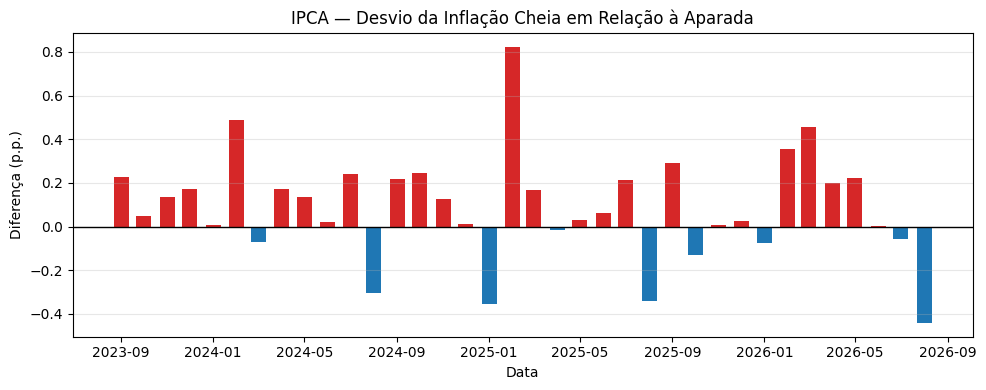

In [98]:
gap_36m = (
    comparacao_aparada
    .tail(36)
    .copy()
)

cores = np.where(
    gap_36m["gap_aparada"] >= 0,
    "tab:red",
    "tab:blue",
)

plt.figure(figsize=(10, 4))

plt.bar(
    gap_36m.index,
    gap_36m["gap_aparada"],
    color=cores,
    width=20,
)

plt.axhline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    "IPCA — Desvio da Inflação Cheia em Relação à Aparada"
)

plt.xlabel("Data")
plt.ylabel("Diferença (p.p.)")

plt.grid(
    True,
    axis="y",
    alpha=0.3,
)

plt.tight_layout()
plt.show()

### 34. Tendência recente da inflação aparada

Para avaliar a direção recente da medida experimental:

$$
\widehat{A}_t^{20}=\alpha+\beta t
$$

O slope indica se o centro da distribuição apresentou direção
crescente ou decrescente na janela recente.

In [99]:
aparada_recente = (
    inflacao_aparada[
        ["aparada_20"]
    ]
    .dropna()
    .tail(13)
    .copy()
)

X_ap = np.arange(
    len(aparada_recente)
).reshape(-1, 1)

modelo_ap = (
    LinearRegression()
    .fit(
        X_ap,
        aparada_recente["aparada_20"],
    )
)

aparada_recente["tendencia"] = (
    modelo_ap.predict(
        X_ap
    )
)

slope_aparada = (
    modelo_ap.coef_[0]
)

cor_slope_ap = (
    "tab:red"
    if slope_aparada > 0
    else "tab:green"
)

seta_ap = (
    "↑"
    if slope_aparada > 0
    else "↓"
)

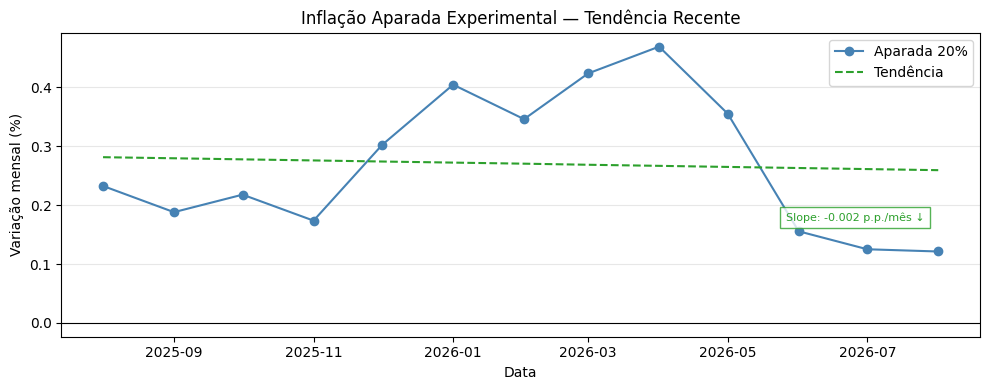

In [100]:
plt.figure(figsize=(10, 4))

plt.plot(
    aparada_recente.index,
    aparada_recente["aparada_20"],
    color="steelblue",
    marker="o",
    linewidth=1.5,
    label="Aparada 20%",
)

plt.plot(
    aparada_recente.index,
    aparada_recente["tendencia"],
    "--",
    color=cor_slope_ap,
    linewidth=1.5,
    label="Tendência",
)

plt.annotate(
    (
        f"Slope: {slope_aparada:+.3f} "
        f"p.p./mês {seta_ap}"
    ),
    (
        aparada_recente.index[-1],
        aparada_recente[
            "aparada_20"
        ].iloc[-1],
    ),
    xytext=(-10, 22),
    textcoords="offset points",
    ha="right",
    fontsize=8,
    color=cor_slope_ap,
    bbox=dict(
        facecolor="white",
        edgecolor=cor_slope_ap,
        alpha=0.8,
    ),
)

plt.axhline(
    0,
    color="black",
    linewidth=0.8,
)

plt.title(
    "Inflação Aparada Experimental — Tendência Recente"
)

plt.xlabel("Data")
plt.ylabel("Variação mensal (%)")

plt.grid(
    True,
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()
plt.show()

---

## PARTE VIII: CHOQUES SETORIAIS



### 35. Onde estão as pressões?

As análises anteriores mostram:

- abrangência;
- heterogeneidade;
- concentração;
- velocidade;
- pressão subjacente.

Agora localizamos as contribuições nos grandes grupos do IPCA.

In [101]:
grupos = pd.read_sql(
    """
    SELECT
        date,
        categoria,
        categoria_nome,
        indice,
        peso
    FROM bcb.ipca_grupos
    ORDER BY date, categoria;
    """,
    engine,
)

grupos["date"] = pd.to_datetime(
    grupos["date"]
)

grupos["contribuicao"] = (
    grupos["indice"]
    * grupos["peso"]
    / 100
)

In [102]:
heat_grupos = (
    grupos
    .groupby(
        [
            "date",
            "categoria_nome",
        ]
    )["contribuicao"]
    .sum()
    .reset_index()
    .pivot(
        index="date",
        columns="categoria_nome",
        values="contribuicao",
    )
    .sort_index()
    .tail(13)
)

heat_grupos.index = (
    heat_grupos.index
    .strftime("%b-%y")
)

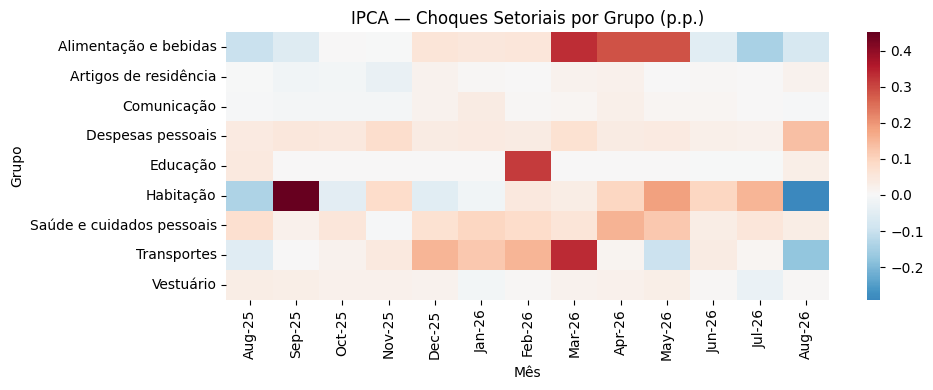

In [126]:
plt.figure(figsize=(10, 4))

sns.heatmap(
    heat_grupos.T,
    cmap="RdBu_r",
    center=0,
    annot=False,
    fmt=".2f",
)

plt.title(
    "IPCA — Choques Setoriais por Grupo (p.p.)"
)

plt.xlabel("Mês")
plt.ylabel("Grupo")

plt.tight_layout()
plt.show()

---

## PARTE IX: TENSÃO INTERNA



### 36. Movimentação escondida pelo agregado

O IPCA é uma soma líquida de contribuições positivas e negativas.

Assim, um IPCA baixo pode surgir de:

* pouca movimentação interna, ou:
* grandes movimentos positivos e negativos se compensando


Definimos uma medida descritiva:

$$
T_t=\sum_i |C_{i,t}|
$$

chamada aqui de **tensão interna**.

Ela NÃO representa inflação.

Ela mede a intensidade total dos movimentos internos.

In [104]:
tensao_interna = (
    subitens
    .groupby(
        "date"
    )["impacto"]
    .sum()
    .rename(
        "tensao_interna"
    )
)

tensao_interna.tail(12)

date
2025-09-01   1.1188
2025-10-01   0.6823
2025-11-01   0.8023
2025-12-01   0.9141
2026-01-01   1.1381
2026-02-01   1.1120
2026-03-01   1.1340
2026-04-01   1.1176
2026-05-01   1.0302
2026-06-01   0.6509
2026-07-01   1.0087
2026-08-01   1.2264
Name: tensao_interna, dtype: float64

---

## PARTE X: PAINEL INTEGRADO



### 37. Visão narrativa do momento

O painel responde quatro perguntas centrais:

* **Momentum** $\to\qquad$ A inflação está ganhando velocidade?
* **Choques** $\to\qquad$ Onde estão as pressões?
* **Difusão** $\to\qquad$ A inflação está se espalhando?
* **Inflação aparada** $\to\qquad$ A pressão permanece após reduzir extremos?


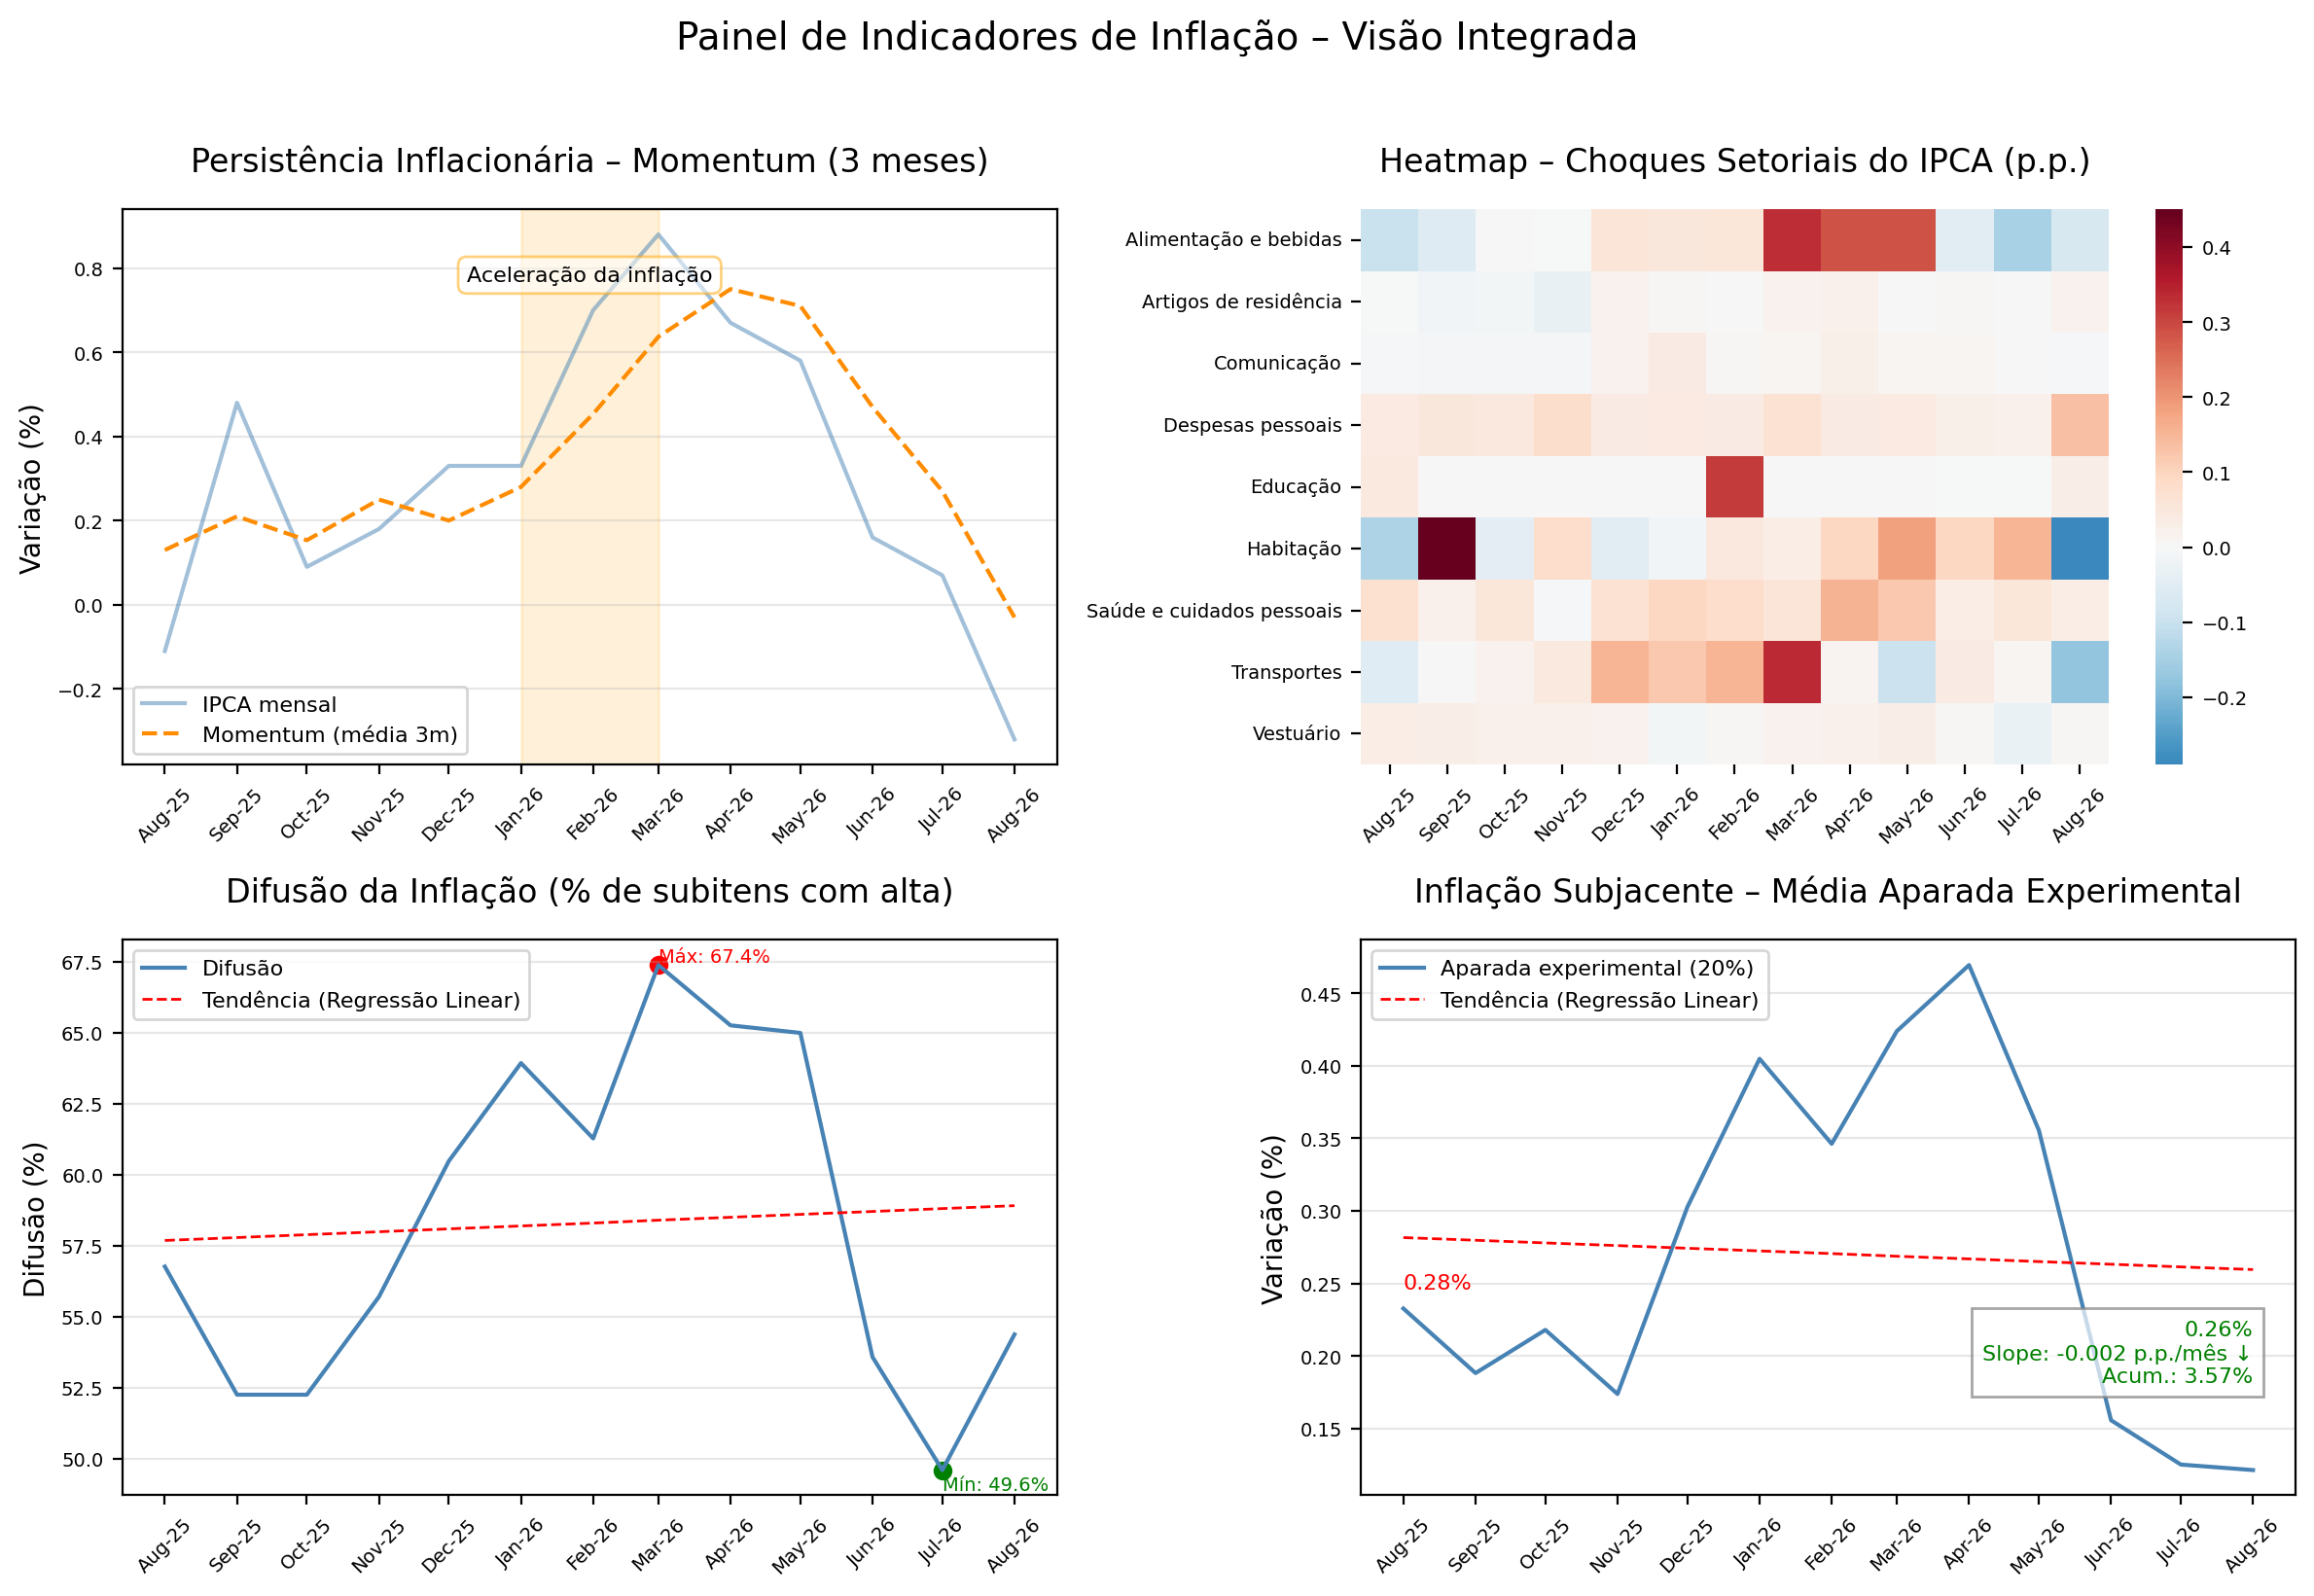

In [136]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8), dpi=200,)


# ============================================================
# 0,0 — MOMENTUM / PERSISTÊNCIA
# ============================================================

mom_plot = momentum_recente.sort_values("date").reset_index(drop=True).copy()

# ------------------------------------------------------------
# ACELERAÇÃO DO IPCA MENSAL
# ------------------------------------------------------------

# Um mês está acelerando quando o IPCA mensal
# é maior que o mês imediatamente anterior
mom_plot["acelera"] = (mom_plot["indice"] > mom_plot["indice"].shift(1))

inicio = None
fim = None

# ------------------------------------------------------------
# Identificar o ÚLTIMO bloco contínuo de aceleração
# ------------------------------------------------------------

acelera = mom_plot["acelera"].fillna(False)

# Encontrar o último mês em aceleração
posicoes = np.flatnonzero(acelera.to_numpy())

if len(posicoes) > 0:
    fim_pos = posicoes[-1]
    inicio_pos = fim_pos

    # Voltar enquanto os meses anteriores
    # também fizerem parte da mesma aceleração
    while (
        inicio_pos > 0
        and acelera.iloc[inicio_pos - 1]
    ):
        inicio_pos -= 1

    # IMPORTANTE:
    # A aceleração começa no mês ANTERIOR ao primeiro aumento,
    # pois é desse nível que começa a subida.
    inicio_plot = max(inicio_pos - 1, 0,)
    inicio = mom_plot["date"].iloc[inicio_plot]
    fim = mom_plot["date"].iloc[fim_pos]


# ------------------------------------------------------------
# IPCA MENSAL E MOMENTUM
# ------------------------------------------------------------

ax[0, 0].plot(mom_plot["date"], mom_plot["indice"], label="IPCA mensal", alpha=0.5, color="steelblue",)
ax[0, 0].plot(mom_plot["date"], mom_plot["mm3"], "--", label="Momentum (média 3m)", linewidth=1.5, color="darkorange",)

# ------------------------------------------------------------
# DESTACAR ÚLTIMA ACELERAÇÃO DO IPCA MENSAL
# ------------------------------------------------------------

if (
    inicio is not None
    and fim is not None
):

    ax[0, 0].axvspan(inicio, fim, color="orange", alpha=0.15, )
    meio = inicio + (fim - inicio) / 2
    
    ax[0, 0].text(
        meio,
        mom_plot["indice"].max() * 0.89,
        "Aceleração da inflação",
        ha="center",
        va="center",
        fontsize=8,
        bbox=dict(boxstyle="round,pad=0.4",facecolor="white",edgecolor="orange",alpha=0.5,),
    )


# ------------------------------------------------------------
# FORMATAÇÃO
# ------------------------------------------------------------

ax[0, 0].set_title("Persistência Inflacionária – Momentum (3 meses)",y=1.04,)
ax[0, 0].set_ylabel("Variação (%)")
ax[0, 0].tick_params(axis="y",labelsize=7,)
ax[0, 0].tick_params(axis="x",labelsize=7,)
ax[0, 0].set_xticks(mom_plot["date"])
ax[0, 0].set_xticklabels(mom_plot["date"].dt.strftime("%b-%y"),rotation=45,)
ax[0, 0].grid(axis="y",alpha=0.3,)
ax[0, 0].legend(fontsize=8)

# ============================================================
# 0,1 — HEATMAP
# ============================================================

sns.heatmap(
    heat_grupos.T,
    cmap="RdBu_r",
    center=0,
    ax=ax[0, 1],
)

# Ajustar fonte do termômetro lateral
cbar = ax[0, 1].collections[0].colorbar
cbar.ax.tick_params(labelsize=7)
ax[0, 1].set_title("Heatmap – Choques Setoriais do IPCA (p.p.)", y=1.04,)
ax[0, 1].set_ylabel("")
ax[0, 1].tick_params(axis="y", labelsize=7,)
ax[0, 1].set_xlabel("")
ax[0, 1].tick_params(axis="x", labelsize=7, rotation=45,)


# ============================================================
# 1,0 — DIFUSÃO
# ============================================================

difusao_painel = difusao.tail(13).copy()

# Converter para percentual
difusao_painel["difusao_pct"] = difusao_painel["difusao"] * 100

# Regressão linear
X = np.arange(len(difusao_painel)).reshape(-1, 1)
y = difusao_painel["difusao_pct"].values

modelo = LinearRegression().fit(X,y,)
tendencia_difusao = modelo.predict(X)
slope_difusao = modelo.coef_[0]

# Máximo e mínimo
max_val = difusao_painel["difusao_pct"].max()
min_val = difusao_painel["difusao_pct"].min()
max_date = difusao_painel["difusao_pct"].idxmax()
min_date = difusao_painel["difusao_pct"].idxmin()

# Gráfico
ax[1, 0].plot(difusao_painel.index, difusao_painel["difusao_pct"],
              linewidth=1.5, color="steelblue", label="Difusão",)
ax[1, 0].plot(difusao_painel.index, tendencia_difusao, "--",
              color="red", linewidth=1, label="Tendência (Regressão Linear)",)

# Máximo
ax[1, 0].scatter(max_date, max_val, color="red",)
ax[1, 0].text(max_date, max_val + 0.1, f"Máx: {max_val:.1f}%", fontsize=7, color="red",)

# Mínimo
ax[1, 0].scatter(min_date, min_val, color="green",)
ax[1, 0].text(min_date, min_val - 0.7, f"Mín: {min_val:.1f}%", fontsize=7, color="green",)
ax[1, 0].set_title("Difusão da Inflação (% de subitens com alta)", y=1.04,)
ax[1, 0].set_ylabel("Difusão (%)")
ax[1, 0].tick_params(axis="y", labelsize=7,)
ax[1, 0].tick_params(axis="x", labelsize=7,)
ax[1, 0].set_xticks(difusao_painel.index)
ax[1, 0].set_xticklabels(difusao_painel.index.strftime("%b-%y"), rotation=45,)
ax[1, 0].grid(axis="y", alpha=0.3,)
ax[1, 0].legend(fontsize=8)


# ============================================================
# 1,1 — INFLAÇÃO APARADA EXPERIMENTAL
# ============================================================

aparada_painel = inflacao_aparada[["aparada_20"]].dropna().tail(13).copy()

# Regressão linear
X = np.arange(len(aparada_painel)).reshape(-1, 1)
y = aparada_painel["aparada_20"].values

modelo = LinearRegression().fit(X, y,)
tendencia_aparada = modelo.predict(X)
t_ini = tendencia_aparada[0]
t_fim = tendencia_aparada[-1]
slope_aparada = modelo.coef_[0]
cor_slope = ( "red" if slope_aparada > 0 else "green")
seta = ("↑" if slope_aparada > 0 else "↓")

# Acumulado composto da janela
acumulado_aparada = ((1 + aparada_painel["aparada_20"] / 100).prod() - 1 ) * 100

# Gráfico
ax[1, 1].plot(aparada_painel.index, aparada_painel["aparada_20"],
              label="Aparada experimental (20%)", linewidth=1.5, color="steelblue",)
ax[1, 1].plot(aparada_painel.index, tendencia_aparada, "--",
              color="red", linewidth=1, label="Tendência (Regressão Linear)",)

# Valor da tendência no início
ax[1, 1].text(aparada_painel.index[0], t_ini - 0.035,
              f"{t_ini:.2f}%", color="red", fontsize=8,)

# Diagnóstico final
ax[1, 1].text(aparada_painel.index[-1], t_fim - 0.08,
              (
                f"{t_fim:.2f}%\n"
                f"Slope: {slope_aparada:.3f} p.p./mês {seta}\n"
                f"Acum.: {acumulado_aparada:.2f}%"
              ),
              color=cor_slope, fontsize=8, ha="right", va="bottom",
              bbox=dict(facecolor="white", alpha=0.7, edgecolor="gray",),)
ax[1, 1].set_title("Inflação Subjacente – Média Aparada Experimental", y=1.04,)
ax[1, 1].set_ylabel("Variação (%)")
ax[1, 1].tick_params(axis="y", labelsize=7,)
ax[1, 1].tick_params(axis="x", labelsize=7,)
ax[1, 1].set_xticks(aparada_painel.index)
ax[1, 1].set_xticklabels(aparada_painel.index.strftime("%b-%y"), rotation=45,)
ax[1, 1].grid(axis="y", alpha=0.3,)
ax[1, 1].legend(fontsize=8)

# ============================================================
# TÍTULO GERAL + ALTA RESOLUÇÃO
# ============================================================

fig.suptitle("Painel de Indicadores de Inflação – Visão Integrada", fontsize=14, y=1.02,)

plt.tight_layout()
plt.show()

---

## PARTE XI: DIAGNÓSTICO DO MOMENTO



### 38. Consolidar indicadores

Esta tabela reúne os principais sinais que poderão orientar
a interpretação econômica do mês mais recente.

In [106]:
indicadores = (
    ipca[
        [
            "date",
            "indice",
            "acumulado12m",
            "aceleracao_3m",
            "gap_curto_medio",
        ]
    ]
    .set_index("date")
    .join(
        difusao[
            [
                "difusao",
                "delta_difusao",
                "mm3",
                "mm6",
            ]
        ].rename(
            columns={
                "mm3":
                "difusao_mm3",
                "mm6":
                "difusao_mm6",
            }
        ),
        how="left",
    )
    .join(
        dispersao[
            [
                "desvio_padrao",
                "iqr",
                "amplitude",
            ]
        ],
        how="left",
    )
    .join(
        concentracao,
        how="left",
    )
    .join(
        inflacao_aparada,
        how="left",
    )
    .join(
        comparacao_aparada[
            ["gap_aparada"]
        ],
        how="left",
    )
    .join(
        tensao_interna,
        how="left",
    )
)

indicadores.tail(12)

,indice,acumulado12m,aceleracao_3m,gap_curto_medio,difusao,delta_difusao,difusao_mm3,difusao_mm6,desvio_padrao,iqr,amplitude,top5,top10,top20,aparada_10,aparada_15,aparada_20,aparada_25,gap_aparada,tensao_interna
date,,,,,,,,,,,,,,,,,,,,
2025-09-01,0.4800,5.1700,-0.1000,-0.0500,0.5225,-0.0451,0.5287,0.5645,3.6956,1.2800,64.3300,0.4867,0.5597,0.6671,0.1449,0.1773,0.1882,0.1656,0.2918,1.1188
2025-10-01,0.0900,4.6800,-0.1000,-0.0500,0.5225,0.0000,0.5376,0.5402,2.2723,1.2400,32.4700,0.2953,0.4031,0.5695,0.2315,0.2350,0.2179,0.2043,-0.1279,0.6823
2025-11-01,0.1800,4.4600,0.1200,0.0600,0.5570,0.0345,0.5340,0.5336,2.6042,1.3600,33.9500,0.2831,0.4097,0.5516,0.2088,0.2380,0.1738,0.1699,0.0062,0.8023
2025-12-01,0.3300,4.2600,-0.0100,-0.0050,0.6048,0.0477,0.5615,0.5451,2.9230,1.2500,38.3900,0.3319,0.4487,0.5881,0.3601,0.3396,0.3026,0.3174,0.0274,0.9141
2026-01-01,0.3300,4.4400,0.1267,0.0633,0.6393,0.0345,0.6004,0.5690,3.0575,1.3500,46.0500,0.3515,0.5122,0.6632,0.5476,0.3966,0.4048,0.4082,-0.0748,1.1381
2026-02-01,0.7000,3.8100,0.2033,0.1017,0.6127,-0.0265,0.6189,0.5765,2.9347,1.5400,49.6400,0.3202,0.4291,0.5670,0.3435,0.3408,0.3462,0.3719,0.3538,1.1120
2026-03-01,0.8800,4.1400,0.4367,0.2183,0.6737,0.0610,0.6419,0.6017,3.4419,1.3800,41.2800,0.3804,0.4661,0.6123,0.4388,0.4118,0.4239,0.4249,0.4561,1.1340
2026-04-01,0.6700,4.3900,0.4700,0.2350,0.6525,-0.0212,0.6463,0.6233,3.0284,1.5900,41.0800,0.3392,0.4252,0.5575,0.6298,0.5963,0.4694,0.4300,0.2006,1.1176
2026-05-01,0.5800,4.7200,0.2567,0.1283,0.6499,-0.0027,0.6587,0.6388,4.1719,1.2400,56.1200,0.4069,0.5310,0.6337,0.2686,0.3448,0.3555,0.3583,0.2245,1.0302


In [123]:
ultimo_mes = (
    indicadores
    .dropna(
        subset=[
            "indice",
            "difusao",
        ]
    )
    .index
    .max()
)

diagnostico_atual = pd.DataFrame(
    [
        {
            "indicador": "IPCA mensal",
            "valor":
            indicadores.loc[
                ultimo_mes,
                "indice",
            ],
        },
        {
            "indicador": "IPCA 12m",
            "valor":
            indicadores.loc[
                ultimo_mes,
                "acumulado12m",
            ],
        },
        {
            "indicador": "Difusão (%)",
            "valor":
            indicadores.loc[
                ultimo_mes,
                "difusao",
            ]
            * 100,
        },
        {
            "indicador":
            "Delta difusão (p.p.)",
            "valor":
            indicadores.loc[
                ultimo_mes,
                "delta_difusao",
            ]
            * 100,
        },
        {
            "indicador":
            "Slope difusão (p.p./mês)",
            "valor":
            slope_difusao,
        },
        {
            "indicador":
            "Aceleração 3m",
            "valor":
            indicadores.loc[
                ultimo_mes,
                "aceleracao_3m",
            ],
        },
        {
            "indicador":
            "Slope momentum",
            "valor":
            slope_momentum,
        },
        {
            "indicador":
            "Aparada experimental 20%",
            "valor":
            indicadores.loc[
                ultimo_mes,
                "aparada_20",
            ],
        },
        {
            "indicador":
            "Slope aparada",
            "valor":
            slope_aparada,
        },
        {
            "indicador":
            "Gap cheio-aparada",
            "valor":
            indicadores.loc[
                ultimo_mes,
                "gap_aparada",
            ],
        },
        {
            "indicador":
            "Concentração Top10 (%)",
            "valor":
            indicadores.loc[
                ultimo_mes,
                "top10",
            ]
            * 100,
        },
        {
            "indicador":
            "IQR",
            "valor":
            indicadores.loc[
                ultimo_mes,
                "iqr",
            ],
        },
        {
            "indicador":
            "Tensão interna",
            "valor":
            indicadores.loc[
                ultimo_mes,
                "tensao_interna",
            ],
        },
    ]
)

diagnostico_atual

,indicador,valor
0,IPCA mensal,-0.3200
1,IPCA 12m,4.2200
2,Difusão (%),54.3767
3,Delta difusão (p.p.),4.7745
4,Slope difusão (p.p./mês),0.1020
5,Aceleração 3m,-0.7400
6,Slope momentum,0.0189
7,Aparada experimental 20%,0.1213
8,Slope aparada,-0.0018
9,Gap cheio-aparada,-0.4413


### 39. Roteiro de leitura

O diagnóstico deve ser construído na seguinte sequência.



1. **Resultado agregado**  
Qual foi o IPCA mensal e qual é o acumulado em 12 meses?

2. **Abrangência**  
A difusão aumentou ou diminuiu?  
O slope recente confirma essa direção?

3. **Heterogeneidade**  
O IQR e o desvio-padrão indicam movimentos muito diferentes entre os componentes?

4. **Concentração**  
Os maiores impactos estão concentrando parcela elevada das pressões?  
Quais subitens dominam esse movimento?

5. **Velocidade**  
A média móvel de três meses está acelerando ou desacelerando?
O slope do momentum confirma a direção recente?

6. **Pressão subjacente**  
A inflação aparada está ganhando ou perdendo força?
O IPCA cheio está acima ou abaixo dela?

7. **Localização**  
Quais grupos aparecem como maiores fontes positivas e negativas no heatmap?

8. **Tensão interna**  
Existe pouca movimentação ou grandes pressões positivas e negativas estão se compensando?

### 40. Matriz narrativa

Algumas combinações ajudam a organizar a investigação.



* **Difusão crescente + momentum crescente**

```text
mais componentes subindo
         +
inflação média ganhando força
         ↓
pressão mais abrangente e mais intensa
```

* **Difusão crescente + momentum decrescente**

```text
mais componentes subindo
         +
intensidade média perdendo força
         ↓
alta disseminada, mas menos intensa
```

* **Difusão decrescente + momentum crescente**

```text
menos componentes pressionando
         +
média ganhando força
         ↓
pressão possivelmente concentrada
```

* **Aparada crescente + difusão crescente**

```text
pressão permanece sem extremos
         +
mais componentes em alta
         ↓
movimento potencialmente mais disseminado
```

* **IPCA baixo + tensão interna alta**

```text
resultado líquido moderado
         +
grande movimentação interna
         ↓
forças positivas e negativas
possivelmente se compensando
```

Essas combinações são roteiros de investigação e não regras
automáticas de classificação.

### 41. Estrutura para storytelling

A leitura mensal pode ser organizada em cinco perguntas:

* **Quanto?**  
Qual foi o IPCA e como está o acumulado em 12 meses?

* **Quão disseminado?**  
Difusão, delta da difusão e slope mostram se as altas estão ganhando ou perdendo abrangência.

* **Quão persistente?**  
MM3, MM6, aceleração e slope do momentum mostram a dinâmica temporal.

* **A pressão permanece além dos extremos?**  
A medida aparada e seu slope ajudam a observar o centro da distribuição.

* **Onde?**  
Heatmap e ranking de impactos mostram onde estão as principais pressões e alívios.

Essa sequência transforma os indicadores em uma narrativa analítica
que pode posteriormente sustentar relatório, dashboard, apresentação
ou comunicação pública.

### 42. O que este notebook NÃO conclui

Os indicadores são predominantemente descritivos.

Portanto:

- slope não é previsão;
- difusão alta não implica necessariamente IPCA alto;
- concentração alta não significa automaticamente problema estrutural;
- média aparada experimental não é núcleo oficial;
- aceleração observada não garante aceleração futura;
- associação entre indicadores não demonstra causalidade.

As interpretações devem surgir dos valores efetivamente observados
e da combinação dos sinais.

---

### 43. Conclusões

Este notebook transforma o IPCA de um único número em um diagnóstico
multidimensional.



* **Abrangência**

$$
D_t
$$

mostra quantos componentes estão em alta.

* **Direção da abrangência**

$$
\Delta D_t
$$

e o slope da difusão mostram se essa abrangência está aumentando
ou diminuindo.

* **Heterogeneidade**

$$
\sigma_{\pi,t}\quad\text{e}\quad IQR_t
$$

mostram quão diferentes são os movimentos entre componentes.

* **Dominância**

$$
K_{k,t}
$$

mostra quanto dos impactos está concentrado nos maiores componentes.

* **Velocidade**

$$
A_t=M_t^{(3)}-M_{t-3}^{(3)}
$$

mede aceleração ou desaceleração da média recente.

* **Persistência**

MM3, MM6 e:

$$
G_t^{CM}=M_t^{(3)}-M_t^{(6)}
$$

ajudam a comparar curto e médio prazo.

* **Pressão subjacente experimental**  
A média aparada reduz a influência dos movimentos extremos e seu
slope permite avaliar a direção recente dessa medida.

* **Localização**  
O heatmap mostra quais grupos produziram contribuições positivas
ou negativas ao longo dos meses recentes.

* **Tensão interna**

$$
T_t=\sum_i|C_{i,t}|
$$

ajuda a identificar períodos em que o IPCA líquido pode esconder
grande movimentação entre os componentes.

---

O diagnóstico passa a seguir:

```text
resultado
    ↓
abrangência
    ↓
heterogeneidade
    ↓
concentração
    ↓
velocidade
    ↓
pressão subjacente
    ↓
localização
    ↓
leitura integrada
```

---



### Próxima etapa

O próximo notebook será:

```text
05.ipca_blocos_macro
```

A pergunta muda de:

> Como está a dinâmica da inflação?

para:

> **De onde economicamente está vindo a inflação?**

Entraremos em classificações econômicas como serviços, alimentação,
monitorados e bens, mantendo a separação do planejamento entre
dinâmica inflacionária, interpretação econômica, política monetária
e futura engenharia de features.